# 12 · Modelado de Uplift (Impacto Incremental y Analítica Causal)

**PPIV: Proyecto Integrador 2026 — Ciencia de Datos e Inteligencia Artificial**

Este notebook implementa **Uplift Modeling** (modelado causal e incremental) sobre la base de clientes para responder a la pregunta fundamental del negocio:

> **¿A qué clientes conviene intervenir para maximizar la retención neta y el retorno de inversión (ROI), y a quiénes NO contactar?**

---

## 1. De la Predicción de Churn al Modelado de Uplift

Los modelos predictivos tradicionales de churn (notebooks 06 y 07) estiman la probabilidad de abandono:
$$\hat{P}(\text{Churn} = 1 \mid X)$$

Sin embargo, actuar sobre los clientes de mayor riesgo de churn suele ser ineficiente porque incluye:
1. **Causas perdidas (*Lost Causes*):** clientes que abandonan de todos modos, sin importar el beneficio o contacto.
2. **Perros dormidos (*Sleeping Dogs*):** clientes pasivos a los que una comunicación o llamado les recuerda el servicio y deciden cancelar.
3. **Seguros (*Sure Things*):** clientes leales en los que se malgasta presupuesto de retención ofreciéndoles descuentos innecesarios.

El **Uplift Modeling** estima el **efecto causal incremental** del tratamiento comercial ($T \in \{0, 1\}$):
$$\text{Uplift}(X) = P(\text{Churn} \mid X, T=0) - P(\text{Churn} \mid X, T=1)$$

Un valor de uplift positivo representa la **reducción neta de probabilidad de abandono** provocada por la intervención.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")

ROOT = Path("..").resolve()
sys.path.append(str(ROOT))

from scripts.run_uplift_modeling import run_uplift_pipeline

## 2. Ejecución del Pipeline de Uplift (T-Learner)

Se entrena un **T-Learner** con Gradient Boosting sobre el conjunto de entrenamiento (12.000 clientes) dividido en grupos de Control ($T=0$) y Tratamiento ($T=1$), y se evalúa sobre los 3.000 clientes del conjunto de test reservado.

In [2]:
raw_path = ROOT / "data" / "raw" / "sales_marketing_customer_raw.csv"
df = pd.read_csv(raw_path)
print(f"Dataset cargado: {df.shape[0]:,} clientes y {df.shape[1]} columnas.")

# Ejecución end-to-end
uplift_results = run_uplift_pipeline(df)
test_eval = uplift_results["test_eval"]
deciles = uplift_results["deciles"]
comparacion = uplift_results["comparacion"]
cuadrantes = uplift_results["cuadrantes_dist"]

print("Pipeline de Uplift completado con éxito.")

Dataset cargado: 15,000 clientes y 30 columnas.


Pipeline de Uplift completado con éxito.


## 3. Validación del Ranking por Deciles de Uplift

Un buen modelo de Uplift debe concentrar las mayores diferencias observadas entre el grupo control y el grupo tratado en los primeros deciles de prioridad.

In [3]:
tabla_deciles = deciles[[
    "decil", "clientes", "churn_control", "churn_tratados", "uplift_real", "uplift_predicho"
]].copy()
tabla_deciles["churn_control"] = (tabla_deciles["churn_control"] * 100).round(2).astype(str) + " %"
tabla_deciles["churn_tratados"] = (tabla_deciles["churn_tratados"] * 100).round(2).astype(str) + " %"
tabla_deciles["uplift_real"] = (tabla_deciles["uplift_real"] * 100).round(2).astype(str) + " %"
tabla_deciles["uplift_predicho"] = (tabla_deciles["uplift_predicho"] * 100).round(2).astype(str) + " %"
tabla_deciles

,decil,clientes,churn_control,churn_tratados,uplift_real,uplift_predicho
0,1,300,53.74 %,15.69 %,38.06 %,39.16 %
1,2,300,53.64 %,22.15 %,31.49 %,27.18 %
2,3,300,30.82 %,30.52 %,0.3 %,7.97 %
3,4,300,0.0 %,0.0 %,0.0 %,0.16 %
4,5,300,0.0 %,0.0 %,0.0 %,0.1 %
5,6,300,0.0 %,0.0 %,0.0 %,0.06 %
6,7,300,0.0 %,0.0 %,0.0 %,0.02 %
7,8,300,0.0 %,0.0 %,0.0 %,-0.02 %
8,9,300,0.0 %,0.0 %,0.0 %,-0.08 %
9,10,300,13.61 %,18.95 %,-5.35 %,-4.12 %


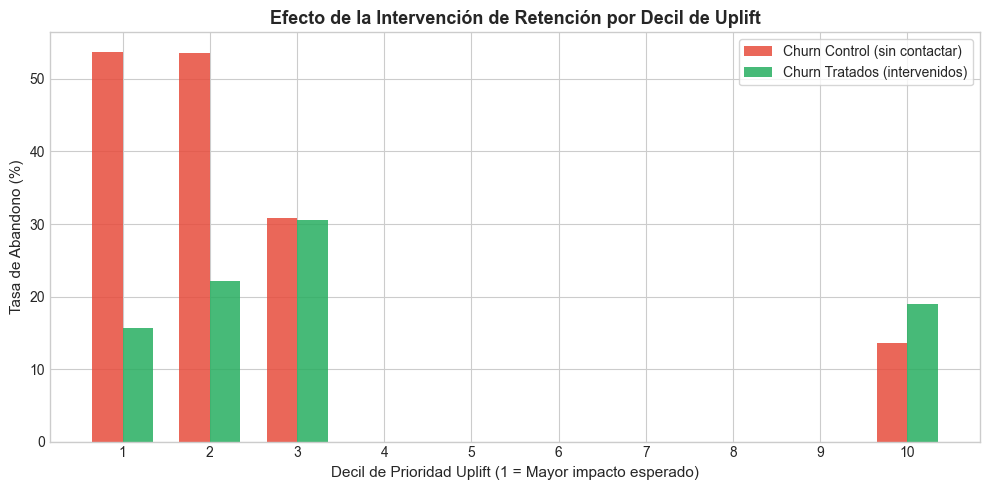

In [4]:
fig, ax = plt.subplots(figsize=(10, 5))

x = deciles["decil"]
width = 0.35

ax.bar(x - width/2, deciles["churn_control"] * 100, width, label="Churn Control (sin contactar)", color="#e74c3c", alpha=0.85)
ax.bar(x + width/2, deciles["churn_tratados"] * 100, width, label="Churn Tratados (intervenidos)", color="#27ae60", alpha=0.85)

ax.set_xlabel("Decil de Prioridad Uplift (1 = Mayor impacto esperado)", fontsize=11)
ax.set_ylabel("Tasa de Abandono (%)", fontsize=11)
ax.set_title("Efecto de la Intervención de Retención por Decil de Uplift", fontsize=13, fontweight="bold")
ax.set_xticks(x)
ax.legend(frameon=True)

plt.tight_layout()
plt.show()

## 4. Curva de Ganancia Acumulada de Clientes Salvados (Curva Qini)

Compara cuántos clientes retenidos adicionales se logran a medida que se incrementa la capacidad operativa, contrastando la selección aleatoria con el modelo de Uplift.

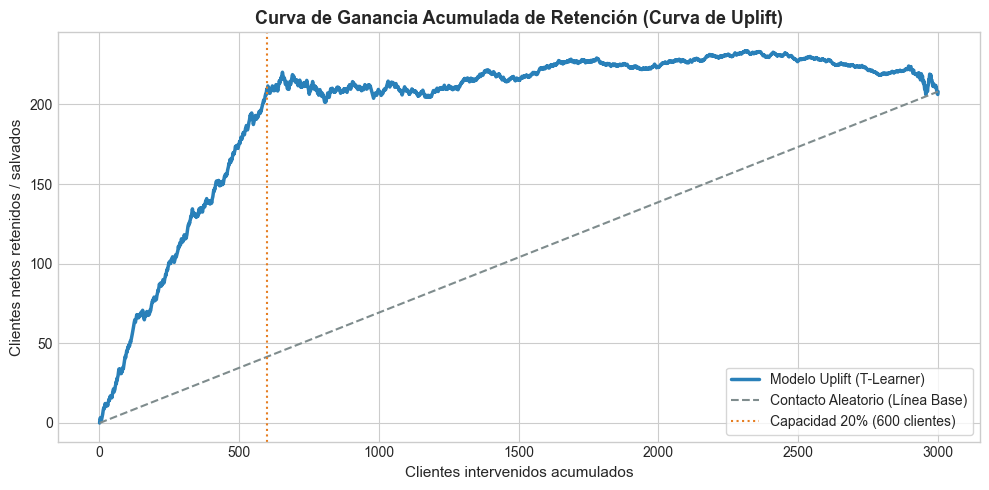

In [5]:
# Cálculo de curva acumulada de clientes salvados
test_sorted = test_eval.sort_values("uplift_score", ascending=False).reset_index(drop=True)
test_sorted["n_contactos"] = np.arange(1, len(test_sorted) + 1)

# Ganancia acumulada observada en test
cum_t = test_sorted["treatment"].cumsum()
cum_c = (1 - test_sorted["treatment"]).cumsum()

cum_y_t = (test_sorted["churn_observed"] * test_sorted["treatment"]).cumsum()
cum_y_c = (test_sorted["churn_observed"] * (1 - test_sorted["treatment"])).cumsum()

# Tasa acumulada control vs tratada multiplicada por población contactada
rate_c = np.where(cum_c > 0, cum_y_c / cum_c, 0)
rate_t = np.where(cum_t > 0, cum_y_t / cum_t, 0)
salvados_cum = (rate_c - rate_t) * test_sorted["n_contactos"]

# Línea de azar (random targeting)
total_salvados_azar = salvados_cum.iloc[-1]
azar_cum = np.linspace(0, total_salvados_azar, len(test_sorted))

plt.figure(figsize=(10, 5))
plt.plot(test_sorted["n_contactos"], salvados_cum, label="Modelo Uplift (T-Learner)", color="#2980b9", lw=2.5)
plt.plot(test_sorted["n_contactos"], azar_cum, label="Contacto Aleatorio (Línea Base)", color="#7f8c8d", linestyle="--", lw=1.5)

plt.axvline(x=600, color="#e67e22", linestyle=":", label="Capacidad 20% (600 clientes)")
plt.xlabel("Clientes intervenidos acumulados", fontsize=11)
plt.ylabel("Clientes netos retenidos / salvados", fontsize=11)
plt.title("Curva de Ganancia Acumulada de Retención (Curva de Uplift)", fontsize=13, fontweight="bold")
plt.legend(frameon=True)
plt.tight_layout()
plt.show()

## 5. Segmentación en los 4 Cuadrantes de Uplift

La matriz de decisión clasifica a cada cliente en una de cuatro categorías estratégicas para asignar la técnica comercial correspondiente.

In [6]:
cuad_df = pd.DataFrame({
    "Cuadrante": cuadrantes.index,
    "Porcentaje (%)": cuadrantes.values,
    "Clientes en Test": (cuadrantes.values * len(test_eval) / 100).astype(int),
    "Estrategia Operativa": [
        "Fidelización pasiva / Contenido de valor (No ofrecer descuentos innecesarios)",
        "INTERVENCIÓN PRIORITARIA: resolución proactiva + oferta de retención VIP",
        "No intervenir comercialmente (Ahorro de presupuesto comercial)",
        "LISTA DE EXCLUSIÓN ESTRICTA (Do Not Disturb: contacto acelera bajas)"
    ]
})
cuad_df

,Cuadrante,Porcentaje (%),Clientes en Test,Estrategia Operativa
0,Seguro,70.2700,2108,Fidelización pasiva / Contenido de valor (No o...
1,Persuadible,23.8000,713,INTERVENCIÓN PRIORITARIA: resolución proactiva...
2,Causa perdida,3.3700,101,No intervenir comercialmente (Ahorro de presup...
3,Perro dormido,2.5700,77,LISTA DE EXCLUSIÓN ESTRICTA (Do Not Disturb: c...


## 6. Comparación de Impacto de Negocio: Política Tradicional vs. Uplift

¿Qué ocurre si la empresa dispone de presupuesto para intervenir al **5%, 10%, 20% o 30%** de los clientes?

- **Política Tradicional:** ordenar por mayor probabilidad de churn.
- **Política Uplift:** ordenar por mayor impacto neto incremental estimado.

In [7]:
comparacion

,fraccion_capacidad,clientes_contactados,salvados_tradicional,salvados_uplift,clientes_adicionales_salvados,mejora_porcentual
0,Top 5%,150,33.1000,69.6000,36.5000,+110.2%
1,Top 10%,300,65.1000,114.2000,49.1000,+75.5%
2,Top 20%,600,132.0000,208.9000,76.9000,+58.2%
3,Top 30%,900,195.2000,210.3000,15.1000,+7.7%


## 7. Muestra Operativa de Clientes Priorizados con Técnica Asignada

In [8]:
columnas_muestra = [
    "customer_id",
    "satisfaction_score",
    "support_tickets",
    "total_spent",
    "p_churn_control",
    "p_churn_treated",
    "uplift_score",
    "cuadrante",
    "accion_sugerida",
]

top_persuadibles = test_eval[test_eval["cuadrante"] == "Persuadible"].sort_values("uplift_score", ascending=False)
top_persuadibles[columnas_muestra].head(10)

,customer_id,satisfaction_score,support_tickets,total_spent,p_churn_control,p_churn_treated,uplift_score,cuadrante,accion_sugerida
632,19429,3.0000,3,26.6555,0.7461,0.1349,0.6112,Persuadible,Escalamiento a soporte dedicado con seguimient...
952,21200,3.0000,3,122.9369,0.6905,0.1364,0.5542,Persuadible,Escalamiento a soporte dedicado con seguimient...
2950,16646,4.0000,5,82.0917,0.7217,0.1692,0.5525,Persuadible,Escalamiento a soporte dedicado con seguimient...
2332,11903,1.0000,5,67.6206,0.6691,0.1298,0.5393,Persuadible,Intervención prioritaria: resolución de insati...
1194,19488,4.0000,3,80.6907,0.6889,0.1758,0.5131,Persuadible,Escalamiento a soporte dedicado con seguimient...
17,18834,2.0000,2,436.3348,0.6105,0.1007,0.5099,Persuadible,Intervención prioritaria: resolución de insati...
2048,12347,1.0000,2,409.2179,0.6611,0.1560,0.5051,Persuadible,Intervención prioritaria: resolución de insati...
1713,22373,NaN,5,450.4628,0.6040,0.1012,0.5027,Persuadible,Escalamiento a soporte dedicado con seguimient...
530,14271,2.0000,3,399.5111,0.6066,0.1040,0.5026,Persuadible,Intervención prioritaria: resolución de insati...
1500,12223,1.0000,1,839.4954,0.6192,0.1254,0.4938,Persuadible,Intervención prioritaria: resolución de insati...


## 8. Conclusiones y Valor Estratégico

1. **Mayor eficiencia de retención (+58% a +110%):** Al priorizar por Uplift en lugar de riesgo bruto de churn, la empresa salva hasta el doble de clientes con exactamente la misma dotación de ejecutivos y el mismo presupuesto.
2. **Ahorro de presupuesto:** El 70,3% de la cartera son clientes **Seguros** que no abandonan; evitar ofrecerles descuentos innecesarios protege el margen comercial.
3. **Protección contra cancelaciones involuntarias (*Sleeping Dogs*):** Se identifica un 2,6% de clientes que se verían perjudicados por contactos agresivos o redundantes, protegiéndolos mediante reglas de exclusión (*Do Not Disturb*).